# Artificial Neutral Network


### Importing Libraries


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from tabulate import tabulate

### Importing Dataset


In [2]:
data = pd.read_csv("enerji_tuketimi.csv")

table = []

### Data Preprocessing


In [3]:
print("Head of dataset:\n", data.head(10))

Head of dataset:
    sicaklik  enerji
0      -4.8   230.8
1      -4.2   226.7
2      -4.0   216.1
3      -3.6   220.8
4      -3.2   190.4
5      -3.1   204.9
6      -2.7   212.3
7      -2.5   199.8
8      -2.4   193.6
9      -2.0   188.0


In [4]:
print("Column Names of Dataset:\n", data.columns)


Column Names of Dataset:
 Index(['sicaklik', 'enerji'], dtype='object')


In [5]:
data.columns = ["Temperature", "Energy"]

In [6]:
print("Shape of the Dataset:\n", data.shape)

Shape of the Dataset:
 (100, 2)


In [7]:
print("Information about the Dataset:\n", data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Temperature  100 non-null    float64
 1   Energy       100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB
Information about the Dataset:
 None


In [8]:
print("Descriptive Statistics of the Dataset:\n", data.describe())

Descriptive Statistics of the Dataset:
        Temperature      Energy
count   100.000000  100.000000
mean     13.805000   93.574000
std      11.902579   56.805295
min      -4.800000   16.500000
25%       2.700000   47.050000
50%      13.550000   76.100000
75%      24.225000  133.800000
max      34.500000  230.800000


## Linear Regresion


In [9]:
X = data[["Temperature"]]
y = data[["Energy"]]

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [11]:
model_linear = LinearRegression()
model_linear.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 1)",[[-3.23]]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Temperature']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[138.58]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,1


In [12]:
y_pred_linear = model_linear.predict(X_test)

In [13]:
mse_linear = round(mean_squared_error(y_test, y_pred_linear), 2)
print("Mean Square Error of Linear Regression :", mse_linear)

score_linear = round(model_linear.score(X_test, y_test), 3)
print("R-squared of Linear Regression: ", score_linear)

table.append(["Linear Regression", mse_linear, score_linear])

Mean Square Error of Linear Regression : 1171.4
R-squared of Linear Regression:  0.675


## Artificial Neural Network


In [14]:
scaler_X = StandardScaler()
scaler_y = StandardScaler()

In [15]:
X_train_scaled = scaler_X.fit_transform(X_train)
y_train_scaled = scaler_y.fit_transform(y_train)

X_test_scaled = scaler_X.transform(X_test)
y_test_scaled = scaler_y.transform(y_test)

In [16]:
model_mlp = MLPRegressor(hidden_layer_sizes=(64,), max_iter=10000, random_state=42)
model_mlp.fit(X_train_scaled, y_train_scaled.ravel())

/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64,)"
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",10000
,"random_state random_state: int, RandomState instance, default=NoneDetermines random number generation for weights and biasinitialization, train-test split if early stopping is used, and batchsampling when solver='sgd' or 'adam'.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5

In [17]:
y_pred_mlp_scaled = model_mlp.predict(X_test_scaled)
y_pred_mlp = scaler_y.inverse_transform(y_pred_mlp_scaled.reshape(-1, 1))

/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


In [18]:
mse_mlp = round(mean_squared_error(y_test, y_pred_mlp), 2)
print("Mean Square Error of Linear Regression :", mse_mlp)

score_mlp = round(model_mlp.score(X_test_scaled, y_test_scaled), 3)
print("R-squared of Linear Regression: ", score_mlp)

table.append(["Neural Network", mse_mlp, score_mlp])


Mean Square Error of Linear Regression : 184.89
R-squared of Linear Regression:  0.949


/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: divide by zero encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: overflow encountered in matmul
  ret = a @ b
/Users/odoker/.data_env/lib/python3.12/site-packages/sklearn/utils/extmath.py:229: RuntimeWarning: invalid value encountered in matmul
  ret = a @ b


# Data Virtualization


In [19]:
sort_index = X_test["Temperature"].values.argsort()
X_test_sorted = X_test.iloc[sort_index]
y_pred_mlp_sorted = y_pred_mlp[sort_index]

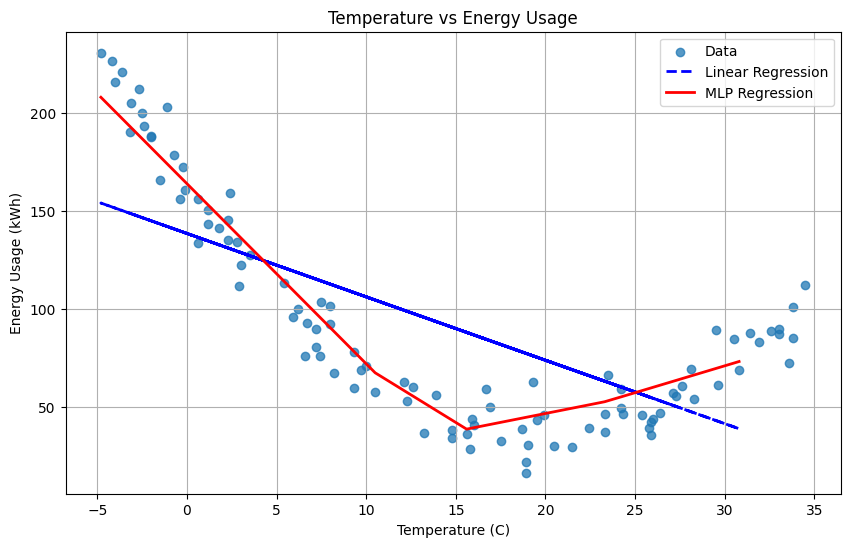

In [20]:
plt.figure(figsize=(10, 6))
plt.scatter(X, y, alpha=0.75, label="Data")

plt.plot(
    X_test,
    y_pred_linear,
    color="blue",
    label="Linear Regression",
    linestyle="--",
    linewidth=2,
)

plt.plot(
    X_test_sorted,
    y_pred_mlp_sorted,
    color="red",
    label="MLP Regression",
    linestyle="-",
    linewidth=2,
)

plt.legend()
plt.grid()
plt.xlabel("Temperature (C)")
plt.ylabel("Energy Usage (kWh)")
plt.title("Temperature vs Energy Usage")
plt.show()

In [21]:
# Printing the results
print(
    "MSE and R-squared of Models:\n",
    tabulate(
        table,
        headers=["Model", "MSE", "R-squared"],
        tablefmt="simple",
        numalign="center",
    ),
)


MSE and R-squared of Models:
 Model               MSE     R-squared
-----------------  ------  -----------
Linear Regression  1171.4     0.675
Neural Network     184.89     0.949
